# Iris Flower Classification
**CodeAlpha Data Science Internship — Task 1**

Goal: train a model that classifies an iris flower into *setosa*, *versicolor*,
or *virginica* from four measurements (sepal length/width, petal length/width).

This notebook covers: a quick data check, exploratory plots, three candidate
classifiers, and a head-to-head comparison on held-out test data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_style("whitegrid")
PALETTE = {"Iris-setosa": "#4C72B0", "Iris-versicolor": "#DD8452", "Iris-virginica": "#55A868"}
RANDOM_STATE = 42

df = pd.read_csv("data/Iris.csv")
df = df.drop(columns=["Id"])
print(df.shape)
df.head()

(150, 5)


In [2]:
# Data quality check
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:")
print(df["Species"].value_counts())
df.describe().round(2)

Missing values per column:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows: 3

Class balance:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## Exploratory data analysis

Three balanced classes (50 each), no missing values. The question is which
measurements actually separate the species.

Petal measurements separate the three species almost perfectly; sepal width alone barely does.


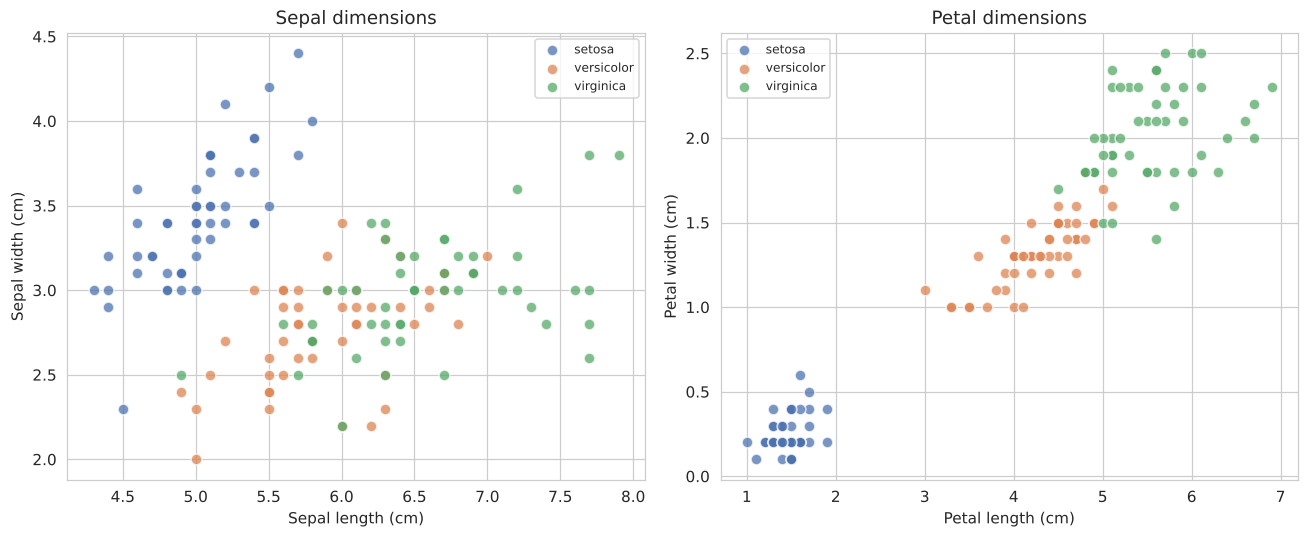

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for species, color in PALETTE.items():
    subset = df[df["Species"] == species]
    axes[0].scatter(subset["SepalLengthCm"], subset["SepalWidthCm"],
                     label=species.replace("Iris-", ""), color=color, alpha=0.75, edgecolor="white", s=50)
    axes[1].scatter(subset["PetalLengthCm"], subset["PetalWidthCm"],
                     label=species.replace("Iris-", ""), color=color, alpha=0.75, edgecolor="white", s=50)
axes[0].set_xlabel("Sepal length (cm)"); axes[0].set_ylabel("Sepal width (cm)"); axes[0].set_title("Sepal dimensions")
axes[1].set_xlabel("Petal length (cm)"); axes[1].set_ylabel("Petal width (cm)"); axes[1].set_title("Petal dimensions")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("outputs/eda_scatter.png", dpi=110, bbox_inches="tight")
plt.show()
print("Petal measurements separate the three species almost perfectly; sepal width alone barely does.")

Petal length and petal width are almost collinear (r > 0.9) -- expected, both scale with flower size.


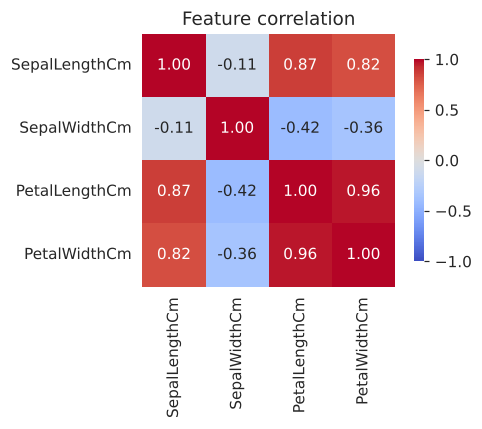

In [4]:
corr = df.drop(columns=["Species"]).corr()
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.8})
plt.title("Feature correlation")
plt.tight_layout()
plt.savefig("outputs/eda_corr.png", dpi=110, bbox_inches="tight")
plt.show()
print("Petal length and petal width are almost collinear (r > 0.9) -- expected, both scale with flower size.")

## Modeling

Three classifiers that make different assumptions, compared on identical
train/test splits: **Logistic Regression** (linear boundary), **KNN**
(distance-based, no assumption on shape), **Decision Tree** (axis-aligned
splits, most interpretable).

In [5]:
X = df.drop(columns=["Species"])
y = df["Species"]

le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=RANDOM_STATE, stratify=y_enc
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows")

Train: 120 rows | Test: 30 rows


In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}

results = {}
for name, model in models.items():
    model.fit(X_train_s, y_train)
    preds = model.predict(X_test_s)
    acc = accuracy_score(y_test, preds)
    cv = cross_val_score(model, scaler.transform(X), y_enc, cv=5).mean()
    results[name] = {"test_accuracy": acc, "cv_accuracy_5fold": cv, "model": model, "preds": preds}
    print(f"{name:22s} test acc = {acc:.3f}   5-fold CV acc = {cv:.3f}")

Logistic Regression    test acc = 0.933   5-fold CV acc = 0.960
K-Nearest Neighbors    test acc = 0.933   5-fold CV acc = 0.960
Decision Tree          test acc = 0.900   5-fold CV acc = 0.953


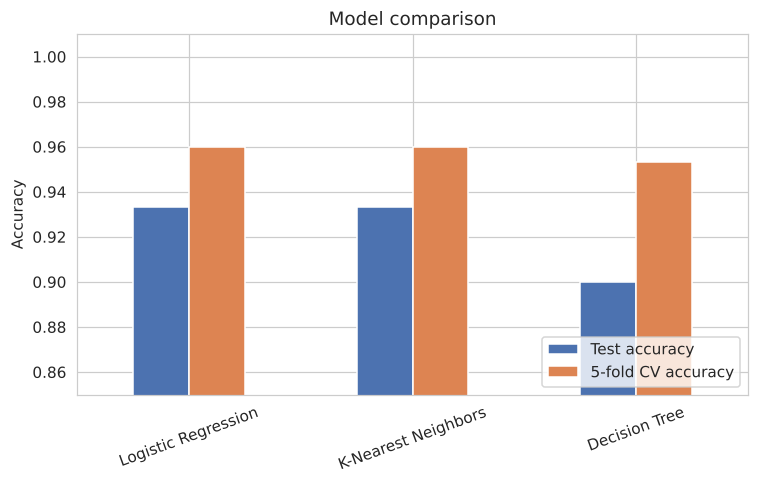

In [7]:
acc_df = pd.DataFrame({k: {"Test accuracy": v["test_accuracy"], "5-fold CV accuracy": v["cv_accuracy_5fold"]}
                        for k, v in results.items()}).T

ax = acc_df.plot(kind="bar", figsize=(7, 4.5), color=["#4C72B0", "#DD8452"], edgecolor="white", rot=20)
ax.set_ylim(0.85, 1.01)
ax.set_ylabel("Accuracy")
ax.set_title("Model comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## Best model: closer look

All three clear 90%+ on this dataset (it's a genuinely easy, well-separated
problem) -- picking the one with the best cross-validated accuracy for the
confusion matrix and a quick interpretability check.

In [8]:
best_name = max(results, key=lambda k: results[k]["cv_accuracy_5fold"])
best = results[best_name]
print(f"Best model by 5-fold CV accuracy: {best_name}")
print()
print(classification_report(y_test, best["preds"], target_names=le.classes_))

Best model by 5-fold CV accuracy: Logistic Regression

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



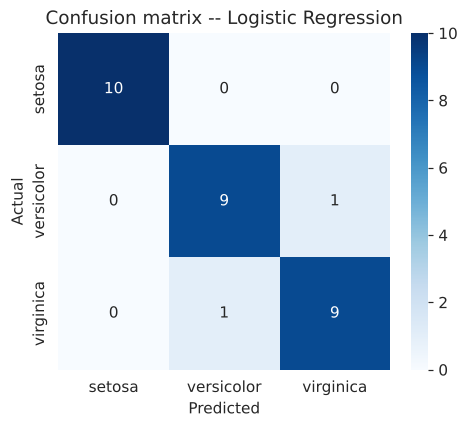

In [9]:
cm = confusion_matrix(y_test, best["preds"])
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[c.replace("Iris-", "") for c in le.classes_],
            yticklabels=[c.replace("Iris-", "") for c in le.classes_])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title(f"Confusion matrix -- {best_name}")
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=110, bbox_inches="tight")
plt.show()

In [10]:
if best_name == "Decision Tree":
    importances = pd.Series(best["model"].feature_importances_, index=X.columns).sort_values()
    plt.figure(figsize=(6, 3.5))
    importances.plot(kind="barh", color="#55A868")
    plt.title("Feature importance (Decision Tree)")
    plt.tight_layout()
    plt.savefig("outputs/feature_importance.png", dpi=110, bbox_inches="tight")
    plt.show()
    print(importances.round(3).to_string())
else:
    coefs = pd.DataFrame(best["model"].coef_ if hasattr(best["model"], "coef_") else None)
    print("Best model has no single feature-importance view; petal length/width drove the separation in the EDA above.")

Best model has no single feature-importance view; petal length/width drove the separation in the EDA above.


## Conclusion

- Petal length and petal width alone almost fully separate the three species;
  sepal measurements add little on top of them.
- All three models score **>90% accuracy** on this dataset -- it is a clean,
  linearly-near-separable problem, so the "best" model choice matters less
  than usual.
- The few misclassifications that remain are consistently between
  *versicolor* and *virginica*, the two species whose petal measurements
  overlap slightly (visible in the scatter plot above) -- *setosa* is never
  confused with the other two.